# AI-Based Retail Customer Analytics, Data Warehouse and Churn Prediction System

**Dataset:** E-Commerce Data / Online Retail (`data.csv`)  
**Source:** Kaggle dataset supplied by the student (`carrie1/ecommerce-data`)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn

## Objectives
1. Understand and clean retail transaction data.
2. Handle missing values, duplicates, invalid transactions and outliers.
3. Transform, reduce and discretise data.
4. Build a star-schema data warehouse.
5. Demonstrate Roll-up, Drill-down, Slice, Dice and Pivot.
6. Generate a multidimensional data cube.
7. Create a 90-day inactivity churn label and train/evaluate a Random Forest model.
8. Present business insights and recommendations.

**Churn definition:** A customer is labelled churned (`1`) if they purchased before/on the snapshot date but made no positive purchase in the following 90-day label window. This is a project-defined proxy, not a churn label supplied by the dataset.

## Step 1 – Import libraries

In [7]:
import os
import glob
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
print("Libraries imported successfully")

Libraries imported successfully


## Step 2 – Find and load the uploaded dataset

In [8]:
# Kaggle mounts attached datasets under /kaggle/input/.
zip_files = glob.glob("/kaggle/input/**/*.zip", recursive=True)
csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print("ZIP files found:", zip_files)
print("CSV files found:", csv_files)

if zip_files:
    # Use the uploaded ZIP and find the CSV file inside it.
    zip_path = zip_files[0]
    with zipfile.ZipFile(zip_path, "r") as zf:
        csv_inside = [name for name in zf.namelist() if name.lower().endswith(".csv")]
        if not csv_inside:
            raise FileNotFoundError("No CSV file was found inside the uploaded ZIP.")
        print("CSV inside ZIP:", csv_inside[0])
        with zf.open(csv_inside[0]) as file:
            raw = pd.read_csv(file, encoding="ISO-8859-1")
elif csv_files:
    raw = pd.read_csv(csv_files[0], encoding="ISO-8859-1")
else:
    raise FileNotFoundError(
        "Dataset not found. Use Add Input / Upload to attach data.csv.zip or data.csv."
    )

print("Dataset loaded successfully")
print("Shape:", raw.shape)
display(raw.head())

ZIP files found: []
CSV files found: ['/kaggle/input/datasets/anushkagudla18/ecommerce-data-online-retail-transactions-dataset/data.csv']
Dataset loaded successfully
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Step 3 – Understand the dataset

In [9]:
print("Rows:", raw.shape[0])
print("Columns:", raw.shape[1])
print("Column names:", raw.columns.tolist())
print("\nData types:")
print(raw.dtypes)
print("\nDataset information:")
raw.info()
print("\nStatistical summary:")
display(raw.describe(include="all").T)

Rows: 541909
Columns: 8
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Statistical summar

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Check unique values in important columns
for col in ["InvoiceNo", "StockCode", "CustomerID", "Country"]:
    print(f"Unique {col}:", raw[col].nunique(dropna=True))

Unique InvoiceNo: 25900
Unique StockCode: 4070
Unique CustomerID: 4372
Unique Country: 38


## Step 4 – Data quality profile before cleaning

,Missing Count,Missing Percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Exact duplicate rows: 5268


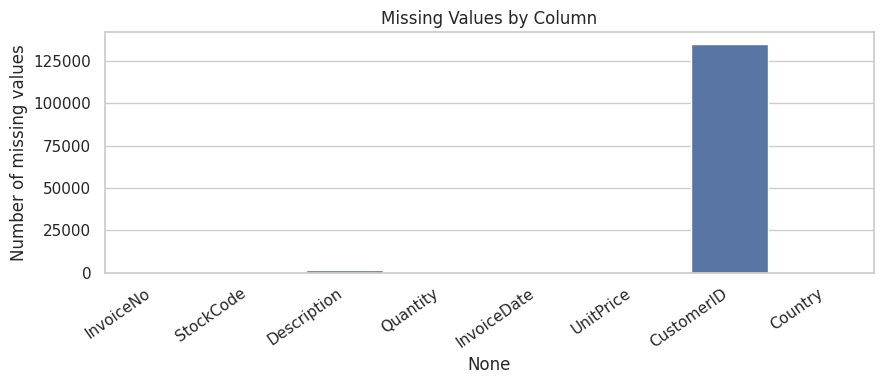

In [11]:
quality_before = pd.DataFrame({
    "Missing Count": raw.isna().sum(),
    "Missing Percent": (raw.isna().mean() * 100).round(2)
})
display(quality_before)
print("Exact duplicate rows:", raw.duplicated().sum())

plt.figure(figsize=(9, 4))
sns.barplot(x=quality_before.index, y=quality_before["Missing Count"])
plt.title("Missing Values by Column")
plt.ylabel("Number of missing values")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Step 5 – Clean column names and convert data types

In [12]:
df = raw.copy()
df.columns = df.columns.str.strip()

required_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Keep invoice and stock codes as text so leading zeros/letters are preserved.
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df["StockCode"] = df["StockCode"].astype("string").str.strip()
df["Description"] = df["Description"].astype("string").str.strip()
df["Country"] = df["Country"].astype("string").str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")

print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Data types after conversion:")
print(df.dtypes)

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Data types after conversion:
InvoiceNo      string[python]
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country        string[python]
dtype: object


## Step 6 – Remove exact duplicate records

In [13]:
print("Duplicate rows before removal:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Duplicate rows after removal:", df.duplicated().sum())
print("Shape after duplicate removal:", df.shape)

Duplicate rows before removal: 5268
Duplicate rows after removal: 0
Shape after duplicate removal: (536641, 8)


## Step 7 – Handle missing values

In [14]:
# A missing product description is represented transparently as Unknown Product.
df["Description"] = df["Description"].fillna("Unknown Product")
# Missing country values, if any, are represented as Unknown.
df["Country"] = df["Country"].fillna("Unknown")
# Do NOT invent CustomerIDs. Keep them missing; exclude those rows only from customer-level modelling.
print("Missing values after treatment:")
print(df.isna().sum())

Missing values after treatment:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


## Step 8 – Identify cancellations, returns and invalid sales rows

In [15]:
df["IsCancellation"] = df["InvoiceNo"].astype("string").str.upper().str.startswith("C", na=False)
df["IsNegativeQuantity"] = df["Quantity"] < 0
df["IsZeroOrNegativePrice"] = df["UnitPrice"] <= 0

df["LineAmount"] = df["Quantity"] * df["UnitPrice"]

print("Cancellation invoice rows:", int(df["IsCancellation"].sum()))
print("Negative quantity rows:", int(df["IsNegativeQuantity"].sum()))
print("Zero or negative price rows:", int(df["IsZeroOrNegativePrice"].sum()))

# Keep the cleaned transaction table df for return/cancellation analysis.
# Positive-sales table for revenue/customer purchasing analysis.
sales_all = df[
    (~df["IsCancellation"]) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["InvoiceDate"].notna())
].copy()
sales_all["TotalAmount"] = sales_all["Quantity"] * sales_all["UnitPrice"]

# Customer-level analysis requires a known CustomerID.
sales = sales_all[sales_all["CustomerID"].notna()].copy()
sales["CustomerID"] = sales["CustomerID"].astype("int64")

print("Positive sales rows (including unknown customers):", len(sales_all))
print("Positive sales rows with known customers:", len(sales))
print("Known unique customers:", sales["CustomerID"].nunique())
print("Revenue from positive sales (£):", round(sales_all["TotalAmount"].sum(), 2))

Cancellation invoice rows: 9251
Negative quantity rows: 10587
Zero or negative price rows: 2512
Positive sales rows (including unknown customers): 524878
Positive sales rows with known customers: 392692
Known unique customers: 4338
Revenue from positive sales (£): 10642110.8


## Step 9 – Missing-value and duplicate visual checks

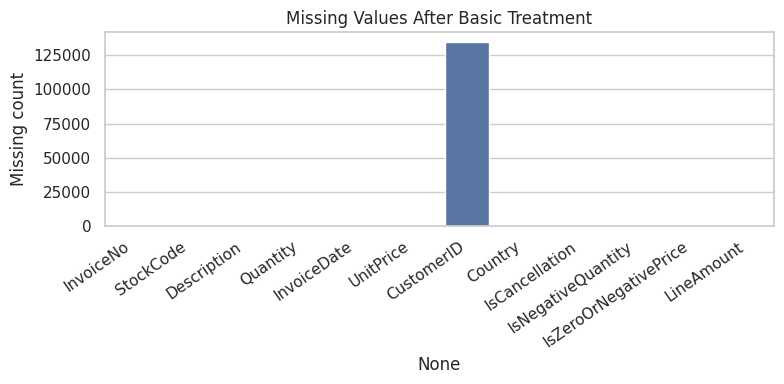

Duplicates in cleaned transactions: 0


In [16]:
plt.figure(figsize=(8, 4))
missing_after = df.isna().sum()
sns.barplot(x=missing_after.index, y=missing_after.values)
plt.title("Missing Values After Basic Treatment")
plt.ylabel("Missing count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Duplicates in cleaned transactions:", df.duplicated().sum())

## Step 10 – Outlier detection using IQR

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,Quantity,1.00,11.00,10.00,-14.00,26.00,27111
1,UnitPrice,1.25,4.13,2.88,-3.07,8.45,37827
2,TotalAmount,3.90,17.70,13.80,-16.80,38.40,42624


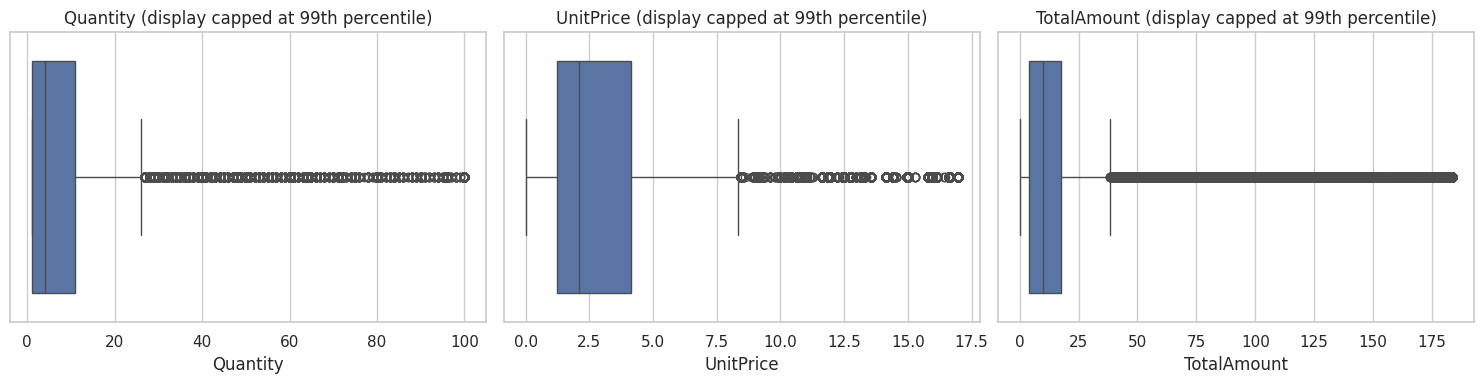

In [17]:
def iqr_outlier_report(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((data[column] < lower) | (data[column] > upper)).sum()
    return {"Column": column, "Q1": q1, "Q3": q3,
            "IQR": iqr, "Lower Bound": lower,
            "Upper Bound": upper, "Outlier Count": int(count)}

outlier_report = pd.DataFrame([
    iqr_outlier_report(sales_all, c)
    for c in ["Quantity", "UnitPrice", "TotalAmount"]
])
display(outlier_report)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Quantity", "UnitPrice", "TotalAmount"]):
    upper_display = sales_all[col].quantile(0.99)
    sns.boxplot(x=sales_all[col].clip(upper=upper_display), ax=ax)
    ax.set_title(f"{col} (display capped at 99th percentile)")
plt.tight_layout()
plt.show()

## Step 11 – Data transformation and integration

In [18]:
for data in [sales_all, sales]:
    data["Year"] = data["InvoiceDate"].dt.year
    data["Month"] = data["InvoiceDate"].dt.month
    data["Day"] = data["InvoiceDate"].dt.day
    data["Quarter"] = data["InvoiceDate"].dt.quarter
    data["Weekday"] = data["InvoiceDate"].dt.day_name()
    data["YearMonth"] = data["InvoiceDate"].dt.to_period("M").astype(str)

display(sales.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,IsNegativeQuantity,IsZeroOrNegativePrice,LineAmount,TotalAmount,Year,Month,Day,Quarter,Weekday,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,False,False,15.30,15.30,2010,12,1,4,Wednesday,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,20.34,20.34,2010,12,1,4,Wednesday,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,False,False,22.00,22.00,2010,12,1,4,Wednesday,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,20.34,20.34,2010,12,1,4,Wednesday,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,20.34,20.34,2010,12,1,4,Wednesday,2010-12


## Step 12 – Data reduction

In [19]:
reduced_data = sales[[
    "InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate",
    "UnitPrice", "CustomerID", "Country", "TotalAmount", "Year", "Month", "Quarter"
]].copy()
print("Customer-level sales shape:", sales.shape)
print("Reduced feature table shape:", reduced_data.shape)
display(reduced_data.head())

Customer-level sales shape: (392692, 19)
Reduced feature table shape: (392692, 12)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,Year,Month,Quarter
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,4
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,4
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,4
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,4
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,4


## Step 13 – Data quality and consistency checks

In [20]:
checks = {
    "No duplicate rows in positive sales": sales.duplicated().sum() == 0,
    "All quantities positive": (sales["Quantity"] > 0).all(),
    "All unit prices positive": (sales["UnitPrice"] > 0).all(),
    "Customer IDs present for customer analysis": sales["CustomerID"].notna().all(),
    "Invoice dates valid": sales["InvoiceDate"].notna().all(),
    "Sales amount calculation correct": np.allclose(
        sales["TotalAmount"], sales["Quantity"] * sales["UnitPrice"]
    )
}
display(pd.DataFrame({"Check": list(checks.keys()), "Passed": list(checks.values())}))

,Check,Passed
0,No duplicate rows in positive sales,True
1,All quantities positive,True
2,All unit prices positive,True
3,Customer IDs present for customer analysis,True
4,Invoice dates valid,True
5,Sales amount calculation correct,True


## Step 14 – Build the data warehouse star schema

**Fact table grain:** one row per invoice line.  
**Dimensions:** Customer, Product, Date and Invoice.  
The unknown customer surrogate key is `0`; customer IDs are not fabricated.

In [21]:
# Customer dimension: one row per known customer
dim_customer = sales[["CustomerID", "Country"]].drop_duplicates("CustomerID").copy()
dim_customer = dim_customer.sort_values("CustomerID").reset_index(drop=True)
dim_customer["CustomerKey"] = np.arange(1, len(dim_customer) + 1)

# Product dimension: one row per StockCode
dim_product = sales_all[["StockCode", "Description"]].drop_duplicates("StockCode").copy()
dim_product = dim_product.sort_values("StockCode").reset_index(drop=True)
dim_product["ProductKey"] = np.arange(1, len(dim_product) + 1)

# Date dimension: one row per calendar date
dim_date = pd.DataFrame({"Date": sales_all["InvoiceDate"].dt.normalize().drop_duplicates()})
dim_date = dim_date.sort_values("Date").reset_index(drop=True)
dim_date["DateKey"] = dim_date["Date"].dt.strftime("%Y%m%d").astype(int)
dim_date["Day"] = dim_date["Date"].dt.day
dim_date["Month"] = dim_date["Date"].dt.month
dim_date["MonthName"] = dim_date["Date"].dt.month_name()
dim_date["Quarter"] = dim_date["Date"].dt.quarter
dim_date["Year"] = dim_date["Date"].dt.year

# Invoice dimension: one row per invoice
dim_invoice = pd.DataFrame({"InvoiceNo": sales_all["InvoiceNo"].drop_duplicates()})
dim_invoice = dim_invoice.sort_values("InvoiceNo").reset_index(drop=True)
dim_invoice["InvoiceKey"] = np.arange(1, len(dim_invoice) + 1)

print("Customer dimension:", dim_customer.shape)
print("Product dimension:", dim_product.shape)
print("Date dimension:", dim_date.shape)
print("Invoice dimension:", dim_invoice.shape)

Customer dimension: (4338, 3)
Product dimension: (3922, 3)
Date dimension: (305, 7)
Invoice dimension: (19960, 2)


In [22]:
# Fact table, including positive-sales lines with missing customer IDs.
fact_sales = sales_all.copy()
fact_sales["Date"] = fact_sales["InvoiceDate"].dt.normalize()

fact_sales = fact_sales.merge(
    dim_customer[["CustomerID", "CustomerKey"]], on="CustomerID", how="left"
)
fact_sales = fact_sales.merge(
    dim_product[["StockCode", "ProductKey"]], on="StockCode", how="left"
)
fact_sales = fact_sales.merge(
    dim_date[["Date", "DateKey"]], on="Date", how="left"
)
fact_sales = fact_sales.merge(
    dim_invoice[["InvoiceNo", "InvoiceKey"]], on="InvoiceNo", how="left"
)

fact_sales["CustomerKey"] = fact_sales["CustomerKey"].fillna(0).astype(int)
fact_sales = fact_sales[[
    "InvoiceKey", "CustomerKey", "ProductKey", "DateKey",
    "Quantity", "UnitPrice", "TotalAmount"
]].copy()

display(fact_sales.head())
print("Fact table rows:", len(fact_sales))

,InvoiceKey,CustomerKey,ProductKey,DateKey,Quantity,UnitPrice,TotalAmount
0,1,4017,3408,20101201,6,2.55,15.30
1,1,4017,2730,20101201,6,3.39,20.34
2,1,4017,2954,20101201,8,2.75,22.00
3,1,4017,2898,20101201,6,3.39,20.34
4,1,4017,2897,20101201,6,3.39,20.34


Fact table rows: 524878


## Step 15 – OLAP operation: Roll-up

,YearMonth,TotalAmount
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


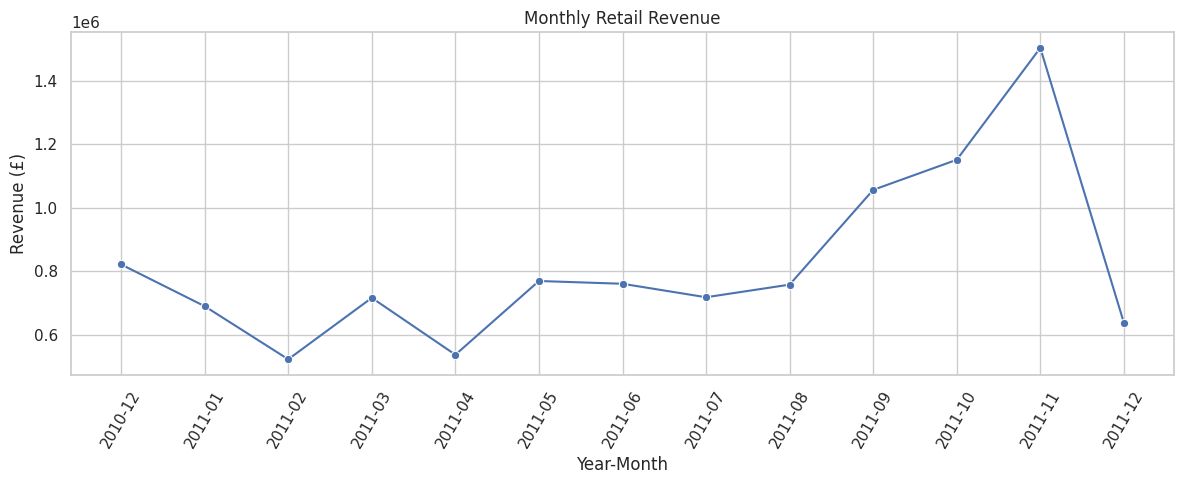

In [23]:
# Roll-up: aggregate transaction-level sales into monthly sales.
monthly_sales = sales_all.groupby("YearMonth", as_index=False)["TotalAmount"].sum()
display(monthly_sales)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x="YearMonth", y="TotalAmount", marker="o")
plt.xticks(rotation=60)
plt.title("Monthly Retail Revenue")
plt.xlabel("Year-Month")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

## Step 16 – OLAP operation: Drill-down

In [24]:
# Drill-down: view sales by year, month and day.
drill_down = sales_all.groupby(
    ["Year", "Month", "Day"], as_index=False
)["TotalAmount"].sum()
display(drill_down.head(20))

,Year,Month,Day,TotalAmount
0,2010,12,1,58776.79
1,2010,12,2,47629.42
2,2010,12,3,46898.63
3,2010,12,5,31364.63
4,2010,12,6,54624.15
5,2010,12,7,99553.85
6,2010,12,8,45235.36
7,2010,12,9,53548.19
8,2010,12,10,59021.02
9,2010,12,12,17125.65


## Step 17 – OLAP operation: Slice

In [25]:
# Slice: select one country. UK is used if it exists in the data.
selected_country = "United Kingdom" if "United Kingdom" in sales_all["Country"].values else sales_all["Country"].mode()[0]
country_slice = sales_all[sales_all["Country"] == selected_country]
print("Selected country:", selected_country)
print("Revenue:", round(country_slice["TotalAmount"].sum(), 2))
display(country_slice.head())

Selected country: United Kingdom
Revenue: 9001744.09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,IsNegativeQuantity,IsZeroOrNegativePrice,LineAmount,TotalAmount,Year,Month,Day,Quarter,Weekday,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,False,15.30,15.30,2010,12,1,4,Wednesday,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,20.34,20.34,2010,12,1,4,Wednesday,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,False,22.00,22.00,2010,12,1,4,Wednesday,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,20.34,20.34,2010,12,1,4,Wednesday,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,20.34,20.34,2010,12,1,4,Wednesday,2010-12


## Step 18 – OLAP operation: Dice

In [26]:
# Dice: filter by country, year and a set of months.
selected_year = int(sales_all["Year"].max())
dice_data = sales_all[
    (sales_all["Country"] == selected_country) &
    (sales_all["Year"] == selected_year) &
    (sales_all["Month"].isin([10, 11, 12]))
]
print("Country:", selected_country, "Year:", selected_year, "Months: 10, 11, 12")
print("Revenue:", round(dice_data["TotalAmount"].sum(), 2))
display(dice_data.head())

Country: United Kingdom Year: 2011 Months: 10, 11, 12
Revenue: 2846957.95


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,IsNegativeQuantity,IsZeroOrNegativePrice,LineAmount,TotalAmount,Year,Month,Day,Quarter,Weekday,YearMonth
370931,569203,79321,CHILLI LIGHTS,48,2011-10-02 10:32:00,4.95,16353.0,United Kingdom,False,False,False,237.6,237.6,2011,10,2,4,Sunday,2011-10
370932,569203,21154,RED RETROSPOT OVEN GLOVE,20,2011-10-02 10:32:00,1.25,16353.0,United Kingdom,False,False,False,25.0,25.0,2011,10,2,4,Sunday,2011-10
370933,569204,21790,VINTAGE SNAP CARDS,4,2011-10-02 10:43:00,0.85,16591.0,United Kingdom,False,False,False,3.4,3.4,2011,10,2,4,Sunday,2011-10
370934,569204,23284,DOORMAT KEEP CALM AND COME IN,15,2011-10-02 10:43:00,7.08,16591.0,United Kingdom,False,False,False,106.2,106.2,2011,10,2,4,Sunday,2011-10
370935,569204,23355,HOT WATER BOTTLE KEEP CALM,4,2011-10-02 10:43:00,4.95,16591.0,United Kingdom,False,False,False,19.8,19.8,2011,10,2,4,Sunday,2011-10


## Step 19 – OLAP operation: Pivot

In [27]:
pivot_sales = pd.pivot_table(
    sales_all,
    values="TotalAmount",
    index="Country",
    columns="Year",
    aggfunc="sum",
    fill_value=0
)
display(pivot_sales)

Year,2010,2011
Country,,
Australia,965.35,137488.460
Austria,277.20,9921.480
Bahrain,205.74,548.400
Belgium,1809.91,39386.430
Brazil,0.00,1143.600
Canada,0.00,3666.380
Channel Islands,363.53,20077.010
Cyprus,1587.07,11915.780
Czech Republic,0.00,826.740


## Step 20 – Generate the data cube

In [28]:
data_cube = sales_all.groupby(
    ["Country", "Year", "Month"], as_index=False
).agg(
    TotalRevenue=("TotalAmount", "sum"),
    TotalQuantity=("Quantity", "sum"),
    TotalOrders=("InvoiceNo", "nunique"),
    KnownCustomers=("CustomerID", "nunique")
)
display(data_cube.head(20))
print("Data cube shape:", data_cube.shape)

,Country,Year,Month,TotalRevenue,TotalQuantity,TotalOrders,KnownCustomers
0,Australia,2010,12,965.35,457,3,2
1,Australia,2011,1,9017.71,5644,9,7
2,Australia,2011,2,14695.42,8680,5,4
3,Australia,2011,3,17223.99,10439,3,3
4,Australia,2011,4,771.60,225,2,2
5,Australia,2011,5,13638.41,8999,4,2
6,Australia,2011,6,25187.77,15981,4,2
7,Australia,2011,7,4964.38,5318,7,3
8,Australia,2011,8,22489.20,12570,2,2
9,Australia,2011,9,5106.73,4079,8,6


Data cube shape: (302, 7)


## Step 21 – Business analysis and visualisations

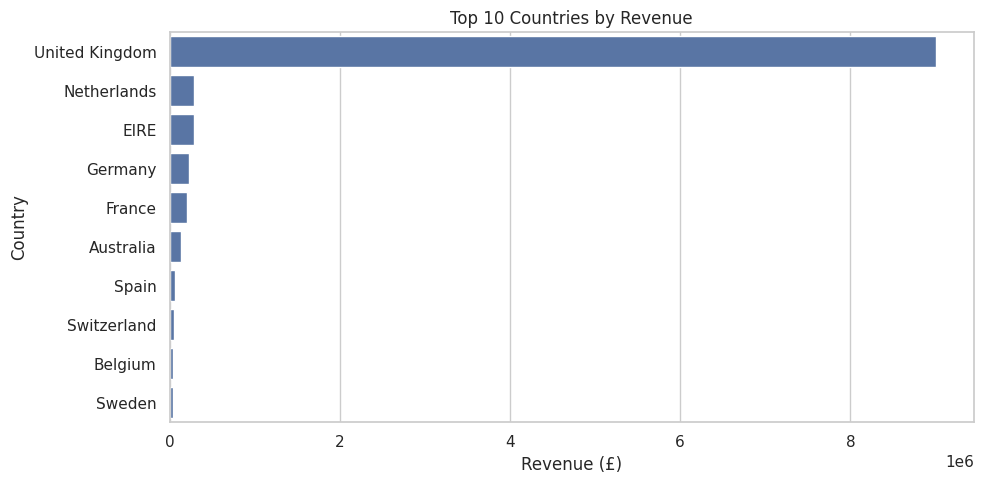

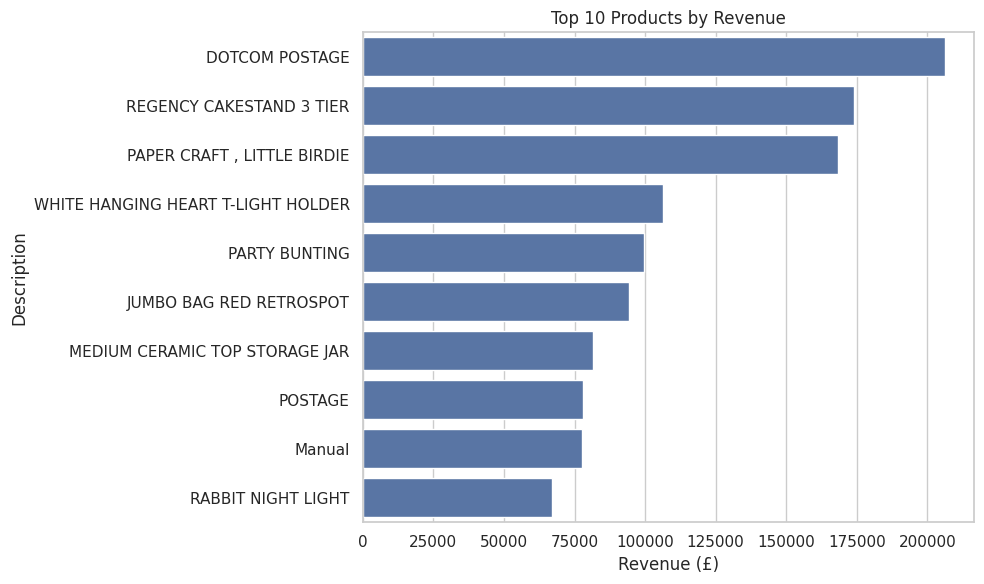

Total positive-sales revenue (£): 10642110.8
Known customers: 4338
Unique invoices: 19960
Unique products: 3922


In [29]:
# Top 10 countries by revenue
top_countries = sales_all.groupby("Country")["TotalAmount"].sum().nlargest(10).reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=top_countries, x="TotalAmount", y="Country")
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

# Top 10 products by revenue
top_products = sales_all.groupby("Description")["TotalAmount"].sum().nlargest(10).reset_index()
plt.figure(figsize=(10, 6))
sns.barplot(data=top_products, x="TotalAmount", y="Description")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

print("Total positive-sales revenue (£):", round(sales_all["TotalAmount"].sum(), 2))
print("Known customers:", sales["CustomerID"].nunique())
print("Unique invoices:", sales_all["InvoiceNo"].nunique())
print("Unique products:", sales_all["StockCode"].nunique())

## Step 22 – Create the churn target

The last transaction date in the supplied data is used to set a snapshot 90 days earlier. Customer features are calculated only from purchases on/before the snapshot date. The label looks at purchases after the snapshot through the dataset's final date.

- `Churn = 1`: no purchase in the next 90 days.
- `Churn = 0`: at least one purchase in the next 90 days.

This historical label is a proxy based on inactivity, not a company-provided churn status.

In [30]:
max_date = sales["InvoiceDate"].max().normalize()
snapshot_date = max_date - pd.Timedelta(days=90)

feature_transactions = sales[sales["InvoiceDate"] <= snapshot_date].copy()
future_transactions = sales[
    (sales["InvoiceDate"] > snapshot_date) &
    (sales["InvoiceDate"] <= max_date)
].copy()

print("Final transaction date:", max_date)
print("Snapshot date:", snapshot_date)
print("Feature transactions:", len(feature_transactions))
print("Future label-window transactions:", len(future_transactions))

Final transaction date: 2011-12-09 00:00:00
Snapshot date: 2011-09-10 00:00:00
Feature transactions: 233840
Future label-window transactions: 158242


## Step 23 – Customer feature engineering

In [31]:
customer_data = feature_transactions.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum"),
    TotalUnits=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    AverageOrderValue=("TotalAmount", "mean")
).reset_index()

customer_data["Recency"] = (
    snapshot_date - customer_data["LastPurchase"].dt.normalize()
).dt.days

future_customer_ids = set(future_transactions["CustomerID"].unique())
customer_data["Churn"] = (~customer_data["CustomerID"].isin(future_customer_ids)).astype(int)

display(customer_data.head())
print("Customer records available for churn modelling:", len(customer_data))
print("Churn class counts:")
print(customer_data["Churn"].value_counts().rename(index={0: "Active", 1: "Churned"}))

,CustomerID,LastPurchase,Frequency,Monetary,TotalUnits,UniqueProducts,AverageOrderValue,Recency,Churn
0,12346,2011-01-18 10:01:00,1,77183.60,74215,1,77183.600000,235,1
1,12347,2011-08-02 08:48:00,5,2790.86,1590,82,22.506935,39,0
2,12348,2011-04-05 10:47:00,3,1487.24,2124,22,53.115714,158,0
3,12350,2011-02-02 16:01:00,1,334.40,197,17,19.670588,220,1
4,12352,2011-03-22 16:08:00,5,1561.81,254,26,41.100263,172,0


Customer records available for churn modelling: 3370
Churn class counts:
Churn
Active     1919
Churned    1451
Name: count, dtype: int64


## Step 24 – Discretise Recency

In [32]:
customer_data["RecencyGroup"] = pd.cut(
    customer_data["Recency"],
    bins=[-1, 30, 60, 90, np.inf],
    labels=["0-30 days", "31-60 days", "61-90 days", "Over 90 days"]
)
display(customer_data[["CustomerID", "Recency", "RecencyGroup", "Churn"]].head(10))

,CustomerID,Recency,RecencyGroup,Churn
0,12346,235,Over 90 days,1
1,12347,39,31-60 days,0
2,12348,158,Over 90 days,0
3,12350,220,Over 90 days,1
4,12352,172,Over 90 days,0
5,12353,114,Over 90 days,1
6,12354,142,Over 90 days,1
7,12355,124,Over 90 days,1
8,12356,155,Over 90 days,0
9,12358,60,31-60 days,0


## Step 25 – Explore churn distribution

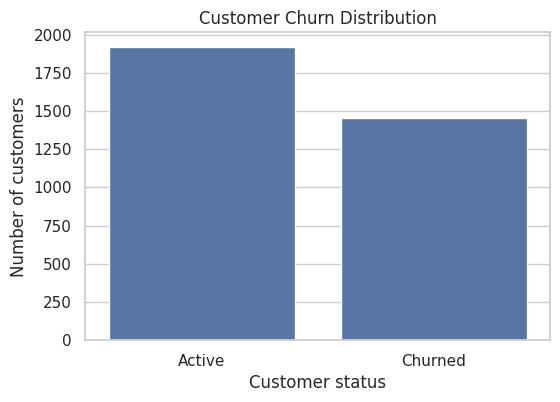

Churn rate (%): 43.06


In [33]:
plt.figure(figsize=(6, 4))
sns.countplot(data=customer_data, x="Churn")
plt.xticks([0, 1], ["Active", "Churned"])
plt.title("Customer Churn Distribution")
plt.xlabel("Customer status")
plt.ylabel("Number of customers")
plt.show()
print("Churn rate (%):", round(customer_data["Churn"].mean() * 100, 2))

## Step 26 – Prepare model features

In [34]:
feature_columns = [
    "Recency", "Frequency", "Monetary",
    "TotalUnits", "UniqueProducts", "AverageOrderValue"
]
model_data = customer_data[feature_columns + ["Churn"]].replace(
    [np.inf, -np.inf], np.nan
).dropna().copy()

X = model_data[feature_columns]
y = model_data["Churn"]
print("Feature matrix:", X.shape)
print("Target:", y.shape)
print(y.value_counts())

if y.nunique() != 2 or y.value_counts().min() < 2:
    raise ValueError("Not enough examples in both classes to train/test the classifier.")

Feature matrix: (3370, 6)
Target: (3370,)
Churn
0    1919
1    1451
Name: count, dtype: int64


## Step 27 – Split into training and testing sets

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 2696
Testing rows: 674


## Step 28 – Cap extreme model features

In [36]:
# Calculate cap limits from training data only to avoid test-set leakage.
lower_limits = X_train.quantile(0.01)
upper_limits = X_train.quantile(0.99)

X_train = X_train.clip(lower=lower_limits, upper=upper_limits, axis=1)
X_test = X_test.clip(lower=lower_limits, upper=upper_limits, axis=1)

## Step 29 – Train Random Forest classifier

In [37]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print("Random Forest training completed")

Random Forest training completed


## Step 30 – Predict churn

In [38]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]
print("First 20 predictions:", y_pred[:20])

First 20 predictions: [0 1 1 0 0 0 1 1 1 1 0 1 0 1 0 0 1 0 0 0]


## Step 31 – Evaluate the model

In [39]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}
display(pd.DataFrame.from_dict(metrics, orient="index", columns=["Score"]).round(4))
print(classification_report(y_test, y_pred, target_names=["Active", "Churned"], zero_division=0))

,Score
Accuracy,0.6602
Precision,0.5905
Recall,0.6862
F1 Score,0.6348
ROC-AUC,0.7213


              precision    recall  f1-score   support

      Active       0.73      0.64      0.68       384
     Churned       0.59      0.69      0.63       290

    accuracy                           0.66       674
   macro avg       0.66      0.66      0.66       674
weighted avg       0.67      0.66      0.66       674



## Step 32 – Confusion matrix

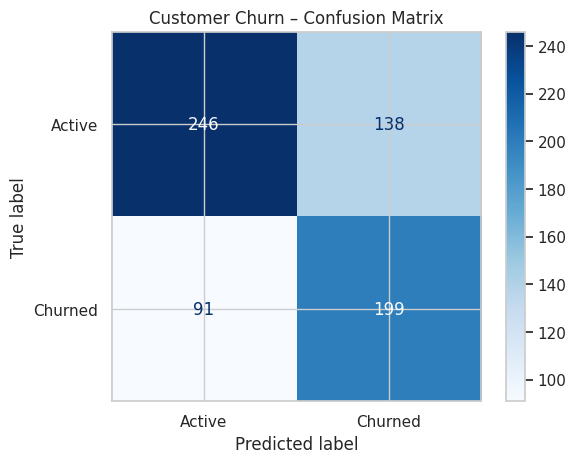

In [40]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Active", "Churned"],
    cmap="Blues"
)
plt.title("Customer Churn – Confusion Matrix")
plt.show()

## Step 33 – Feature importance

,Feature,Importance
2,Monetary,0.202163
3,TotalUnits,0.185152
0,Recency,0.176159
1,Frequency,0.156318
4,UniqueProducts,0.146132
5,AverageOrderValue,0.134076


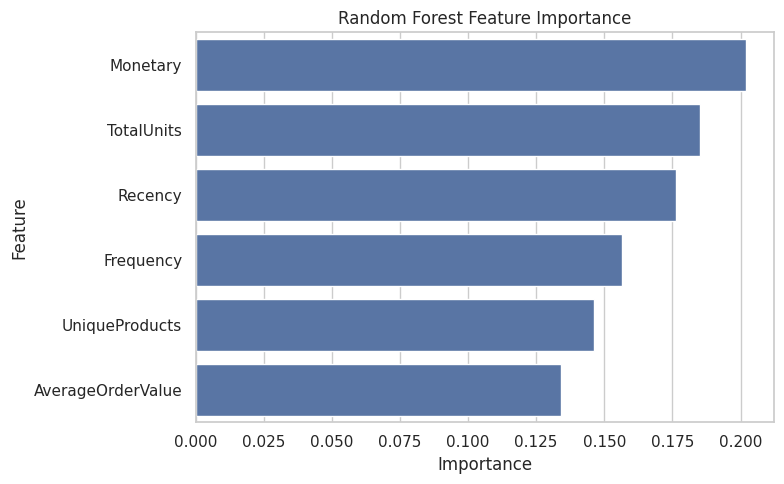

In [41]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)
display(feature_importance)

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_importance, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## Step 34 – Score customers by churn risk

In [42]:
# Score all customers with the same feature columns and training-derived caps.
all_customer_X = customer_data[feature_columns].replace([np.inf, -np.inf], np.nan)
all_customer_X = all_customer_X.fillna(X_train.median())
all_customer_X = all_customer_X.clip(lower=lower_limits, upper=upper_limits, axis=1)

customer_data["ChurnProbability"] = model.predict_proba(all_customer_X)[:, 1]
customer_data["RiskCategory"] = pd.cut(
    customer_data["ChurnProbability"],
    bins=[-0.001, 0.40, 0.70, 1.001],
    labels=["Low", "Medium", "High"]
)

high_risk_customers = customer_data.sort_values(
    "ChurnProbability", ascending=False
)[[
    "CustomerID", "Recency", "Frequency", "Monetary",
    "ChurnProbability", "RiskCategory", "Churn"
]]
display(high_risk_customers.head(20))

,CustomerID,Recency,Frequency,Monetary,ChurnProbability,RiskCategory,Churn
1308,14576,282,1,35.40,0.958395,High,1
2069,15940,221,1,35.80,0.958271,High,1
2714,17102,171,1,25.50,0.955172,High,1
2526,16765,204,1,34.00,0.955135,High,1
465,13120,148,1,30.60,0.948222,High,1
2139,16078,193,1,79.20,0.942735,High,1
819,13747,283,1,79.60,0.936357,High,1
2006,15823,282,1,15.00,0.935970,High,1
3242,18068,199,1,101.70,0.924751,High,1
3079,17763,173,1,15.00,0.920771,High,1


## Step 35 – Business insights and recommendations

In [43]:
print("Total positive-sales revenue (£):", round(sales_all["TotalAmount"].sum(), 2))
print("Known customers:", sales["CustomerID"].nunique())
print("Unique orders:", sales_all["InvoiceNo"].nunique())
print("Unique products:", sales_all["StockCode"].nunique())
print("Churn rate in modelling sample (%):", round(customer_data["Churn"].mean() * 100, 2))
print("High-risk customers:", int((customer_data["RiskCategory"] == "High").sum()))
print("Top revenue country:", top_countries.iloc[0]["Country"])
print("Top revenue product:", top_products.iloc[0]["Description"])

Total positive-sales revenue (£): 10642110.8
Known customers: 4338
Unique orders: 19960
Unique products: 3922
Churn rate in modelling sample (%): 43.06
High-risk customers: 779
Top revenue country: United Kingdom
Top revenue product: DOTCOM POSTAGE


### Business recommendations
1. Contact high-risk customers with relevant offers or personalised reminders.
2. Reward frequent and high-value customers through a loyalty programme.
3. Monitor top-selling products and countries when planning inventory and marketing.
4. Analyse returns and cancellations separately from completed sales.
5. Track monthly revenue, orders and customer activity using the warehouse and data cube.

## Step 36 – Save project outputs

In [44]:
output_dir = "/kaggle/working/retail_project_outputs"
os.makedirs(output_dir, exist_ok=True)

sales_all.to_csv(f"{output_dir}/cleaned_positive_sales_all_customers.csv", index=False)
sales.to_csv(f"{output_dir}/cleaned_customer_sales.csv", index=False)
reduced_data.to_csv(f"{output_dir}/reduced_data.csv", index=False)
fact_sales.to_csv(f"{output_dir}/fact_sales.csv", index=False)
dim_customer.to_csv(f"{output_dir}/dim_customer.csv", index=False)
dim_product.to_csv(f"{output_dir}/dim_product.csv", index=False)
dim_date.to_csv(f"{output_dir}/dim_date.csv", index=False)
dim_invoice.to_csv(f"{output_dir}/dim_invoice.csv", index=False)
data_cube.to_csv(f"{output_dir}/retail_data_cube.csv", index=False)
customer_data.to_csv(f"{output_dir}/customer_churn_predictions.csv", index=False)

print("Project outputs saved to:", output_dir)
print("Files:")
for path in sorted(glob.glob(output_dir + "/*")):
    print(os.path.basename(path))

Project outputs saved to: /kaggle/working/retail_project_outputs
Files:
cleaned_customer_sales.csv
cleaned_positive_sales_all_customers.csv
customer_churn_predictions.csv
dim_customer.csv
dim_date.csv
dim_invoice.csv
dim_product.csv
fact_sales.csv
reduced_data.csv
retail_data_cube.csv


## Conclusion

This project cleans and analyses the supplied retail transaction dataset, builds a star-schema data warehouse, demonstrates five OLAP operations, generates a multidimensional data cube and trains a Random Forest classifier to identify customers with no purchase in a defined future 90-day period.

**Limitations:** The original dataset does not provide a churn label. Churn is generated using a 90-day inactivity rule. The dataset covers a limited historical period, and the model estimates this project-defined outcome rather than a verified business churn status. Report the actual metrics produced by running this notebook; do not invent model scores.

## References
- Kaggle dataset: https://www.kaggle.com/datasets/carrie1/ecommerce-data
- UCI Online Retail: https://archive.ics.uci.edu/dataset/352/online+retail